# Image restoration: inverse and Wiener filtering

**Data model.** For an $M\times N$ image $f(x,y)$ (0–255), motion-blur PSF $h(x,y)$ and additive noise $n(x,y)$:

$$g(x,y) = (h \circledast f)(x,y) + n(x,y) \quad\Longleftrightarrow\quad G(u,v) = H(u,v)F(u,v) + N(u,v)$$

Assumptions: the convolution is **circular** (so the DFT relation is exact), $n$ is i.i.d. zero-mean Gaussian with variance $\sigma^2$ (white, $S_n(u,v)=\sigma^2$), independent of $f$, and $h$ is known.

**Filters** (both implemented by hand; only `fft2`/`ifft2` from numpy):
* Inverse filter: $\hat F = G/H$, with a threshold $\varepsilon$: frequencies with $|H|\le\varepsilon$ are set to 0.
* Wiener filter (MMSE linear estimator): $\hat F = \dfrac{H^*}{|H|^2 + S_n/S_f}\,G$.
  * *oracle*: $S_f = |F|^2/MN$ from the true image (upper bound, not usable in practice),
  * *constant K*: $S_n/S_f \approx K$, a single scalar.

**Metrics:** $\mathrm{MSE} = \frac{1}{MN}\sum (f-\hat f)^2$, $\mathrm{PSNR} = 10\log_{10}(255^2/\mathrm{MSE})$ dB.

I1 (220, 220) 21.0 240.0
I2 (256, 256) 0.0 255.0


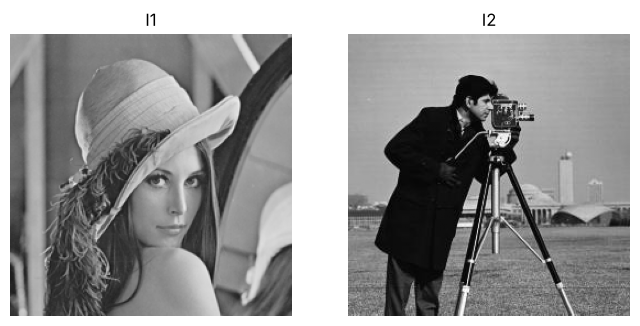

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import restoration as r

rng = np.random.default_rng(0)          # fixed seed: reproducible noise
imgs = r.load_images("img_restoration.mat")
for k, f in imgs.items():
    print(k, f.shape, f.min(), f.max())

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, (k, f) in zip(ax, imgs.items()):
    a.imshow(f, cmap="gray", vmin=0, vmax=255); a.set_title(k); a.axis("off")
plt.show()

## 1. Motion-blur PSF and its transfer function
Linear motion of `L` pixels at angle `theta`. $|H(u,v)|$ has (near-)zeros along lines perpendicular to the motion: these are the frequencies the inverse filter cannot recover.

min |H| = 2.523358571116961e-06   fraction of |H| < 0.01: 0.06694214876033058


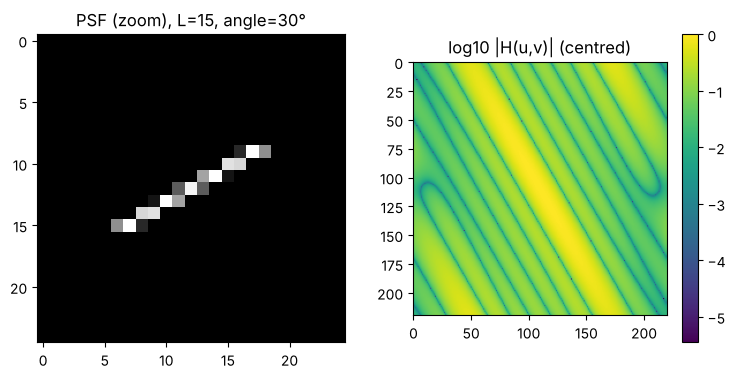

In [2]:
L, THETA = 15, 30          # blur length (pixels) and angle (degrees)
SIGMA = 10                 # noise std on the 0-255 scale

f = imgs["I1"]
psf = r.motion_psf(L, THETA, f.shape)
H = r.transfer_function(psf)
print("min |H| =", np.abs(H).min(), "  fraction of |H| < 0.01:", np.mean(np.abs(H) < 0.01))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(np.fft.fftshift(psf)[f.shape[0]//2-12:f.shape[0]//2+13, f.shape[1]//2-12:f.shape[1]//2+13], cmap="gray")
ax[0].set_title(f"PSF (zoom), L={L}, angle={THETA}°")
im = ax[1].imshow(np.log10(np.abs(np.fft.fftshift(H)) + 1e-6), cmap="viridis")
ax[1].set_title("log10 |H(u,v)| (centred)"); plt.colorbar(im, ax=ax[1])
plt.show()

## 2. Degradations: blur only, noise only, blur + noise

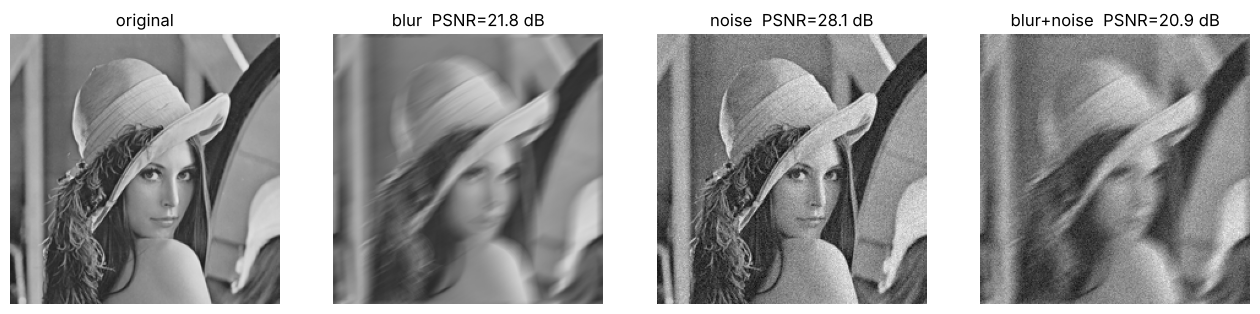

In [3]:
def degrade(f, H, sigma, rng):
    return {
        "blur":       r.blur(f, H),
        "noise":      r.add_noise(f, sigma, rng),
        "blur+noise": r.add_noise(r.blur(f, H), sigma, rng),
    }

deg = degrade(f, H, SIGMA, rng)
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(f, cmap="gray", vmin=0, vmax=255); ax[0].set_title("original")
for a, (k, g) in zip(ax[1:], deg.items()):
    a.imshow(g, cmap="gray", vmin=0, vmax=255); a.set_title(f"{k}  PSNR={r.psnr(f, g):.1f} dB")
for a in ax: a.axis("off")
plt.show()

## 3. Inverse filter
Without noise, the plain inverse ($\varepsilon=0$) is essentially perfect (the error is floating-point round-off). With noise, $N/H$ explodes wherever $|H|$ is small; thresholding trades that noise amplification against losing the frequencies that are set to zero.

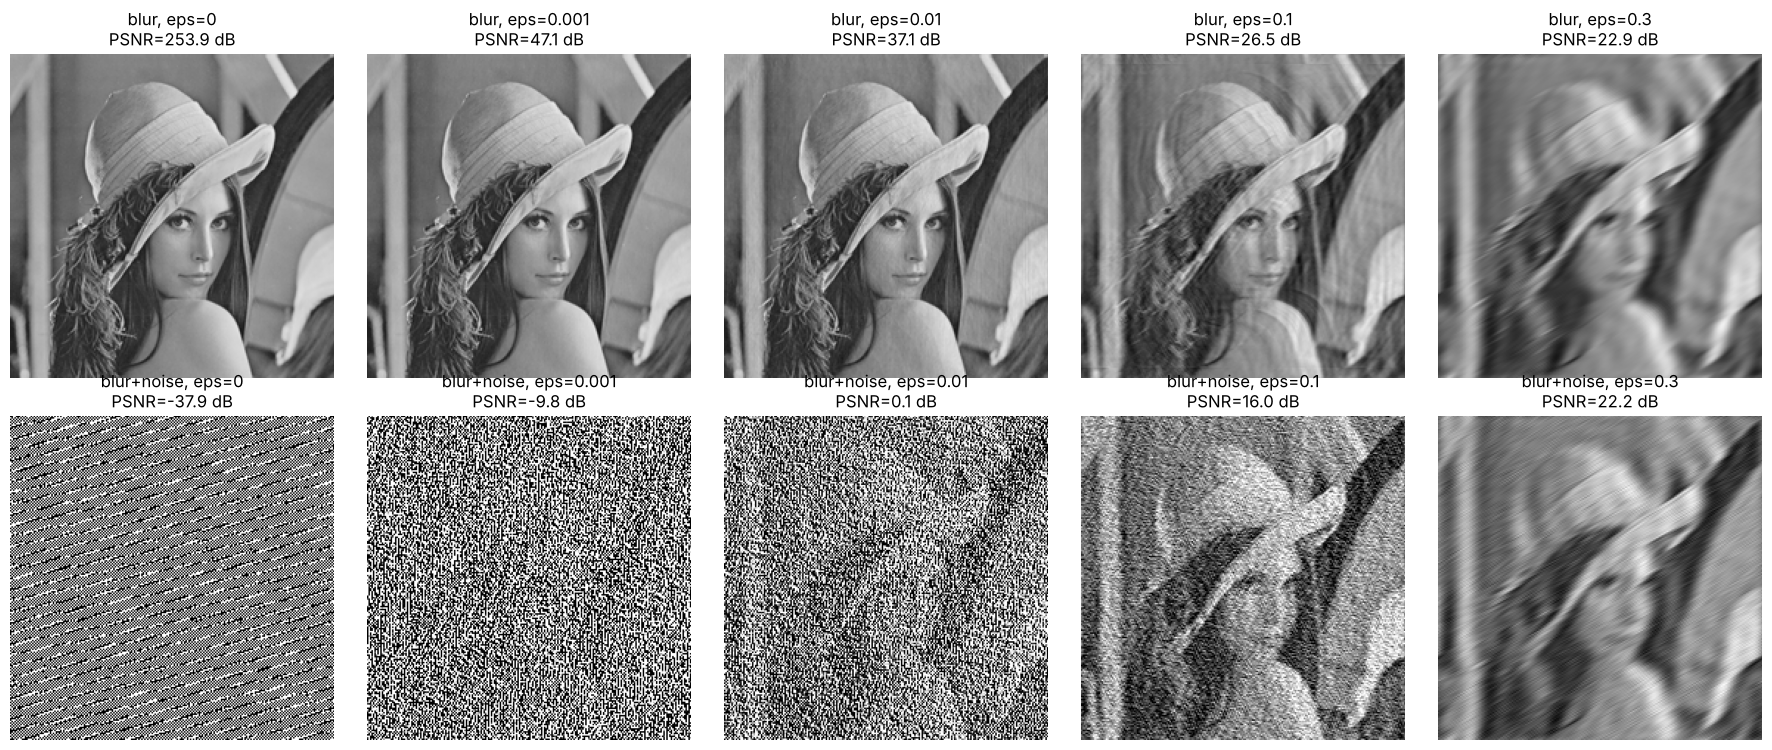

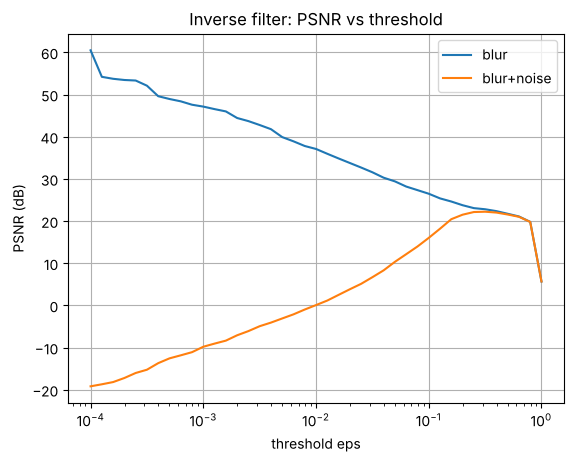

In [4]:
eps_list = [0, 1e-3, 1e-2, 1e-1, 0.3]
fig, ax = plt.subplots(2, len(eps_list), figsize=(18, 7.5))
for row, case in enumerate(["blur", "blur+noise"]):
    for a, eps in zip(ax[row], eps_list):
        fh = r.inverse_filter(deg[case], H, eps)
        a.imshow(np.clip(fh, 0, 255), cmap="gray", vmin=0, vmax=255)
        a.set_title(f"{case}, eps={eps}\nPSNR={r.psnr(f, fh):.1f} dB"); a.axis("off")
plt.tight_layout(); plt.show()

eps_grid = np.logspace(-4, 0, 41)
for case in ["blur", "blur+noise"]:
    plt.semilogx(eps_grid, [r.psnr(f, r.inverse_filter(deg[case], H, e)) for e in eps_grid], label=case)
plt.xlabel("threshold eps"); plt.ylabel("PSNR (dB)"); plt.title("Inverse filter: PSNR vs threshold"); plt.legend(); plt.grid(True); plt.show()

## 4. Wiener filter
The constant $K$ is chosen by a grid search on MSE (uses the ground truth, so it is an optimistic choice) and also with the simple estimate $K=\sigma^2/(\widehat{\mathrm{var}}(g)-\sigma^2)$, which needs only $g$ and $\sigma$.

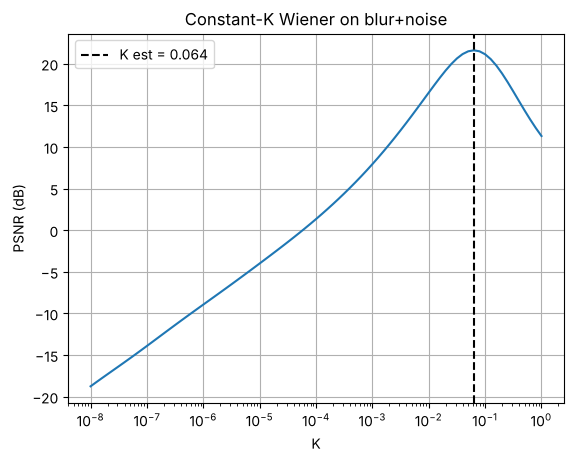

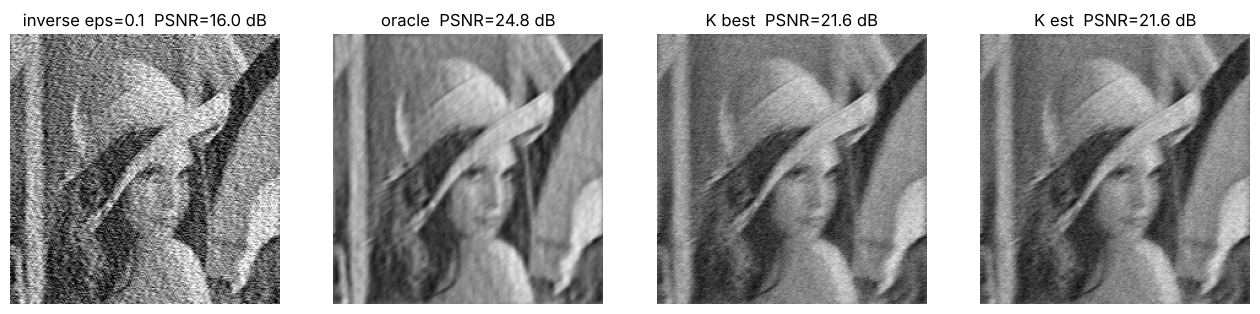

In [5]:
K_grid = np.logspace(-8, 0, 81)

def wiener_variants(g, H, f, sigma):
    out = {"oracle": r.wiener_filter(g, H, r.oracle_nsr(f, sigma))}
    p = [r.psnr(f, r.wiener_filter(g, H, K)) for K in K_grid]
    out["K best"] = r.wiener_filter(g, H, K_grid[int(np.argmax(p))])
    K_est = sigma**2 / max(g.var() - sigma**2, 1e-6)
    out["K est"] = r.wiener_filter(g, H, K_est)
    return out, p, K_est

g = deg["blur+noise"]
w, p, K_est = wiener_variants(g, H, f, SIGMA)
plt.semilogx(K_grid, p); plt.axvline(K_est, ls="--", c="k", label=f"K est = {K_est:.2g}")
plt.xlabel("K"); plt.ylabel("PSNR (dB)"); plt.title("Constant-K Wiener on blur+noise"); plt.legend(); plt.grid(True); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
fh_inv = r.inverse_filter(g, H, 0.1)
for a, (k, fh) in zip(ax, [("inverse eps=0.1", fh_inv)] + list(w.items())):
    a.imshow(np.clip(fh, 0, 255), cmap="gray", vmin=0, vmax=255)
    a.set_title(f"{k}  PSNR={r.psnr(f, fh):.1f} dB"); a.axis("off")
plt.show()

## 5. Summary table: all distortions, both images
Noise-only uses $H=1$: the inverse filter is then the identity, while the Wiener filter becomes a pure denoiser $S_f/(S_f+S_n)$.

In [6]:
def run_all(f, H, sigma, rng):
    rows = []
    ones = np.ones_like(H)
    for case, g in degrade(f, H, sigma, rng).items():
        HH = ones if case == "noise" else H
        s = sigma if "noise" in case else 1e-3   # tiny sigma for the noiseless case avoids 0/0
        res = {"degraded": g, "inverse eps=0": r.inverse_filter(g, HH, 0),
               "inverse eps=0.1": r.inverse_filter(g, HH, 0.1)}
        w, _, _ = wiener_variants(g, HH, f, s)
        res.update({"Wiener " + k: v for k, v in w.items()})
        for method, fh in res.items():
            rows.append((case, method, r.mse(f, fh), r.psnr(f, fh)))
    return rows

for name, f_ in imgs.items():
    H_ = r.transfer_function(r.motion_psf(L, THETA, f_.shape))
    print(f"\n{name}  (L={L}, angle={THETA}°, sigma={SIGMA})")
    print(f"{'distortion':<12}{'method':<18}{'MSE':>12}{'PSNR [dB]':>11}")
    for case, method, m, p in run_all(f_, H_, SIGMA, rng):
        print(f"{case:<12}{method:<18}{m:>12.2f}{p:>11.2f}")


I1  (L=15, angle=30°, sigma=10)
distortion  method                     MSE  PSNR [dB]


blur        degraded                427.21      21.82
blur        inverse eps=0             0.00     253.94
blur        inverse eps=0.1         146.42      26.47
blur        Wiener oracle             0.04      62.45
blur        Wiener K best             0.08      59.04
blur        Wiener K est              0.01      69.92
noise       degraded                100.19      28.12
noise       inverse eps=0           100.19      28.12
noise       inverse eps=0.1         100.19      28.12
noise       Wiener oracle            39.13      32.21
noise       Wiener K best            99.59      28.15
noise       Wiener K est            123.14      27.23
blur+noise  degraded                528.60      20.90
blur+noise  inverse eps=0     850467847.99     -41.17
blur+noise  inverse eps=0.1        1633.54      16.00
blur+noise  Wiener oracle           218.78      24.73
blur+noise  Wiener K best           449.85      21.60
blur+noise  Wiener K est            449.86      21.60

I2  (L=15, angle=30°, sigma

blur        degraded                588.21      20.44
blur        inverse eps=0             0.00     261.68
blur        inverse eps=0.1         238.09      24.36
blur        Wiener oracle             0.03      62.84
blur        Wiener K best             0.08      59.33
blur        Wiener K est              0.01      70.82
noise       degraded                 99.78      28.14
noise       inverse eps=0            99.78      28.14
noise       inverse eps=0.1          99.78      28.14
noise       Wiener oracle            48.43      31.28
noise       Wiener K best            99.21      28.17
noise       Wiener K est            105.98      27.88
blur+noise  degraded                687.52      19.76
blur+noise  inverse eps=0      70100595.23     -30.33
blur+noise  inverse eps=0.1        1738.27      15.73
blur+noise  Wiener oracle           334.60      22.89
blur+noise  Wiener K best           567.85      20.59
blur+noise  Wiener K est            659.26      19.94


## 6. PSNR versus noise level (blur + noise, I1)

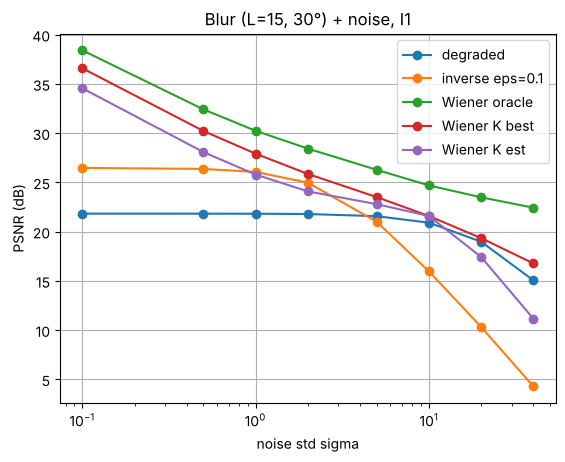

In [7]:
sigmas = [0.1, 0.5, 1, 2, 5, 10, 20, 40]
curves = {k: [] for k in ["degraded", "inverse eps=0.1", "Wiener oracle", "Wiener K best", "Wiener K est"]}
for s in sigmas:
    g = r.add_noise(r.blur(f, H), s, rng)
    w, _, _ = wiener_variants(g, H, f, s)
    curves["degraded"].append(r.psnr(f, g))
    curves["inverse eps=0.1"].append(r.psnr(f, r.inverse_filter(g, H, 0.1)))
    for k, v in w.items(): curves["Wiener " + k].append(r.psnr(f, v))
for k, v in curves.items(): plt.semilogx(sigmas, v, "o-", label=k)
plt.xlabel("noise std sigma"); plt.ylabel("PSNR (dB)"); plt.legend(); plt.grid(True)
plt.title(f"Blur (L={L}, {THETA}°) + noise, I1"); plt.show()

true sigma = 10, estimated sigma = 10.15, fitted alpha = 2.89


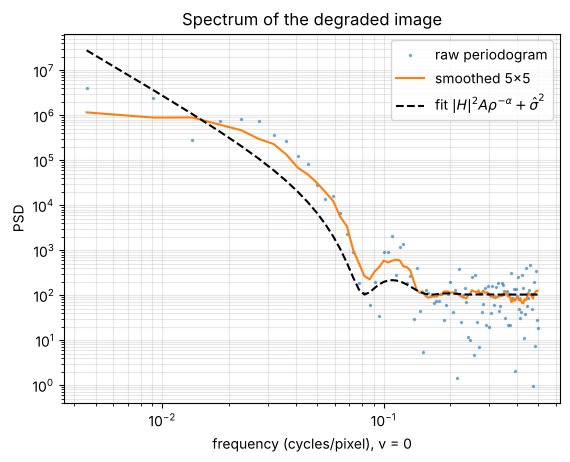

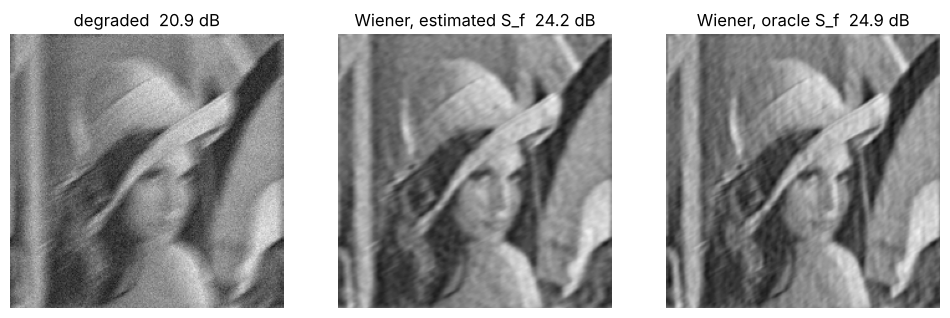

In [8]:
g = r.add_noise(r.blur(f, H), SIGMA, rng)
s_hat = r.estimate_noise_sigma(g)
A, alpha, S_f_hat = r.fit_power_law_spectrum(g, H, s_hat)
print(f"true sigma = {SIGMA}, estimated sigma = {s_hat:.2f}, fitted alpha = {alpha:.2f}")

# Compare the raw periodogram, the smoothed one and the fitted model along one frequency axis
rho = r.radial_frequency(f.shape)
P_raw = np.abs(np.fft.fft2(g - g.mean()))**2 / g.size
P_s = r.smoothed_periodogram(g)
model = np.abs(H)**2 * S_f_hat + s_hat**2
n = f.shape[1] // 2
plt.loglog(rho[0, 1:n], P_raw[0, 1:n], ".", ms=3, alpha=.5, label="raw periodogram")
plt.loglog(rho[0, 1:n], P_s[0, 1:n], label="smoothed 5x5")
plt.loglog(rho[0, 1:n], model[0, 1:n], "k--", label=r"fit $|H|^2 A\rho^{-\alpha}+\hat\sigma^2$")
plt.xlabel("frequency (cycles/pixel), v = 0"); plt.ylabel("PSD"); plt.legend(); plt.grid(True, which="both", alpha=.3)
plt.title("Spectrum of the degraded image"); plt.show()

fh_est = r.wiener_filter(g, H, s_hat**2 / S_f_hat)
fh_orc = r.wiener_filter(g, H, r.oracle_nsr(f, SIGMA))
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (k, im) in zip(ax, [("degraded", g), ("Wiener, estimated S_f", fh_est), ("Wiener, oracle S_f", fh_orc)]):
    a.imshow(np.clip(im, 0, 255), cmap="gray", vmin=0, vmax=255); a.set_title(f"{k}  {r.psnr(f, im):.1f} dB"); a.axis("off")
plt.show()

In [9]:
def wiener_est(g, H):
    s = r.estimate_noise_sigma(g)
    _, _, Sf = r.fit_power_law_spectrum(g, H, s)
    return r.wiener_filter(g, H, s**2 / Sf)

print(f"{'image':<6}{'sigma':>6}{'sigma_hat':>11}{'degraded':>10}{'inv eps=0.1':>12}{'W const K':>11}{'W estimated':>13}{'W oracle':>10}")
for name, f_ in imgs.items():
    H_ = r.transfer_function(r.motion_psf(L, THETA, f_.shape))
    for s in [1, 5, 10, 20]:
        g_ = r.add_noise(r.blur(f_, H_), s, rng)
        Kest = s**2 / max(g_.var() - s**2, 1e-6)
        print(f"{name:<6}{s:>6}{r.estimate_noise_sigma(g_):>11.2f}{r.psnr(f_, g_):>10.2f}"
              f"{r.psnr(f_, r.inverse_filter(g_, H_, 0.1)):>12.2f}{r.psnr(f_, r.wiener_filter(g_, H_, Kest)):>11.2f}"
              f"{r.psnr(f_, wiener_est(g_, H_)):>13.2f}{r.psnr(f_, r.wiener_filter(g_, H_, r.oracle_nsr(f_, s))):>10.2f}")

image  sigma  sigma_hat  degraded inv eps=0.1  W const K  W estimated  W oracle
I1         1       1.35     21.82       26.06      25.79        28.94     30.16
I1         5       5.24     21.57       20.97      22.74        25.55     26.15


I1        10      10.08     20.94       15.99      21.58        24.20     24.75
I1        20      20.08     18.97       10.28      17.48        23.01     23.52
I2         1       1.40     20.43       24.10      23.98        26.72     28.54


I2         5       5.26     20.27       20.23      20.56        23.46     24.30
I2        10      10.14     19.75       15.82      20.04        22.40     23.07
I2        20      19.98     18.18       10.28      18.63        21.42     21.87


The power-law Wiener filter needs only $g$ and $h$, yet gets within about 0.5–2 dB of the oracle and is clearly better than the constant-$K$ version. The constant $K$ assumes a white image spectrum, which is badly wrong: the image power falls by orders of magnitude from low to high frequencies.